In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# Load dataset
df = pd.read_csv('Unemployment_Rate_upto_11_2020.csv')

# Clean column names (strip trailing/leading spaces)
df.columns = df.columns.str.strip()

# Shape inspection and null check
print("Dataset Shape:", df.shape)
print("\nNull Values per Column:\n", df.isnull().sum())
print("\nData Types:\n", df.dtypes)

# Convert Date column to datetime
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')

# Preview clean data
print(df.head())

Matplotlib is building the font cache; this may take a moment.


Dataset Shape: (267, 9)

Null Values per Column:
 Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Region.1                                   0
longitude                                  0
latitude                                   0
dtype: int64

Data Types:
 Region                                      object
Date                                        object
Frequency                                   object
Estimated Unemployment Rate (%)            float64
Estimated Employed                           int64
Estimated Labour Participation Rate (%)    float64
Region.1                                    object
longitude                                  float64
latitude                                   float64
dtype: object
           Region       Date Frequency  Estim

In [4]:
# Calculate average unemployment rate by region/state
region_unemployment = df.groupby('Region')['Estimated Unemployment Rate (%)'].mean().reset_index()
region_unemployment = region_unemployment.sort_values(by='Estimated Unemployment Rate (%)', ascending=False)

print("Top 10 States by Average Unemployment Rate:")
print(region_unemployment.head(10))

Top 10 States by Average Unemployment Rate:
              Region  Estimated Unemployment Rate (%)
7            Haryana                        27.477000
23           Tripura                        25.055000
10         Jharkhand                        19.539000
2              Bihar                        19.471000
4              Delhi                        18.414000
17        Puducherry                        17.942000
9    Jammu & Kashmir                        16.477778
8   Himachal Pradesh                        16.065000
19         Rajasthan                        15.868000
21        Tamil Nadu                        12.187000


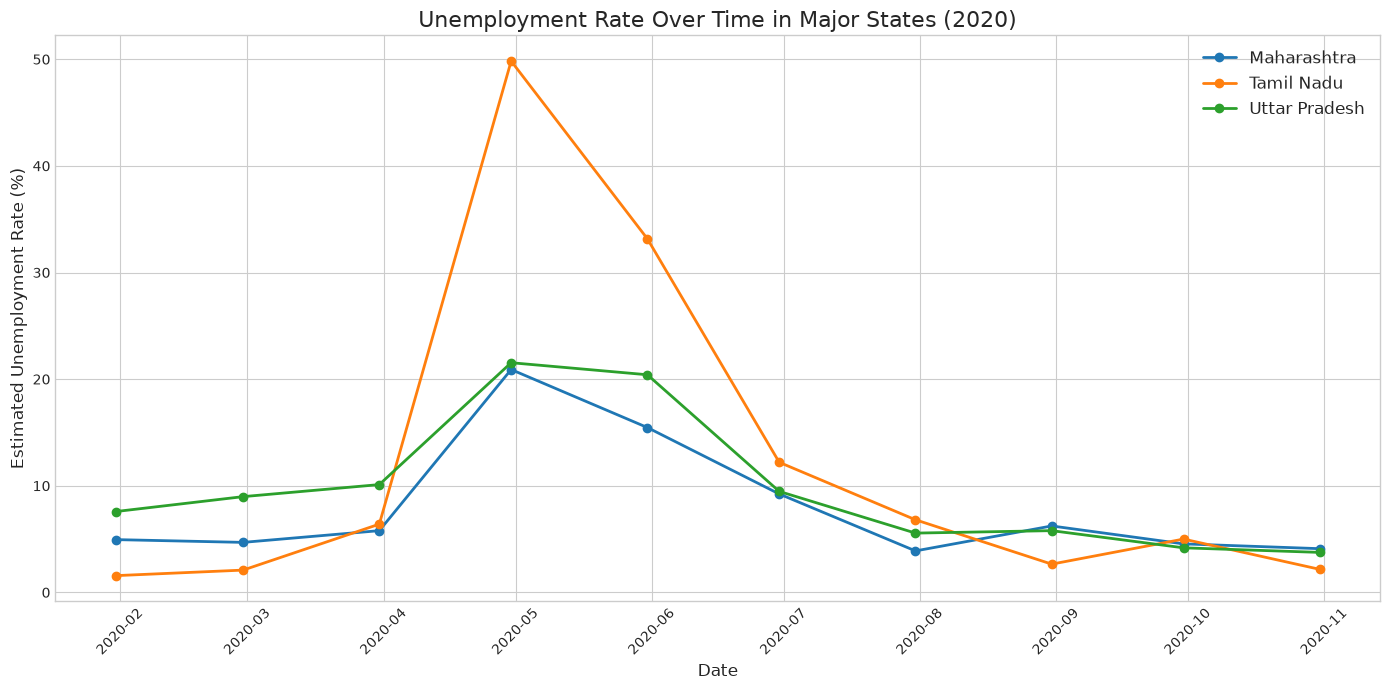

In [2]:
# Select 3 major states to track over time
major_states = ['Maharashtra', 'Tamil Nadu', 'Uttar Pradesh']
filtered_df = df[df['Region'].isin(major_states)]

plt.figure(figsize=(14, 7))
for state in major_states:
    state_data = filtered_df[filtered_df['Region'] == state].sort_values('Date')
    plt.plot(state_data['Date'], state_data['Estimated Unemployment Rate (%)'], marker='o', linewidth=2, label=state)

plt.title('Unemployment Rate Over Time in Major States (2020)', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Estimated Unemployment Rate (%)', fontsize=12)
plt.legend(fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

/tmp/ipykernel_2501/2516645985.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


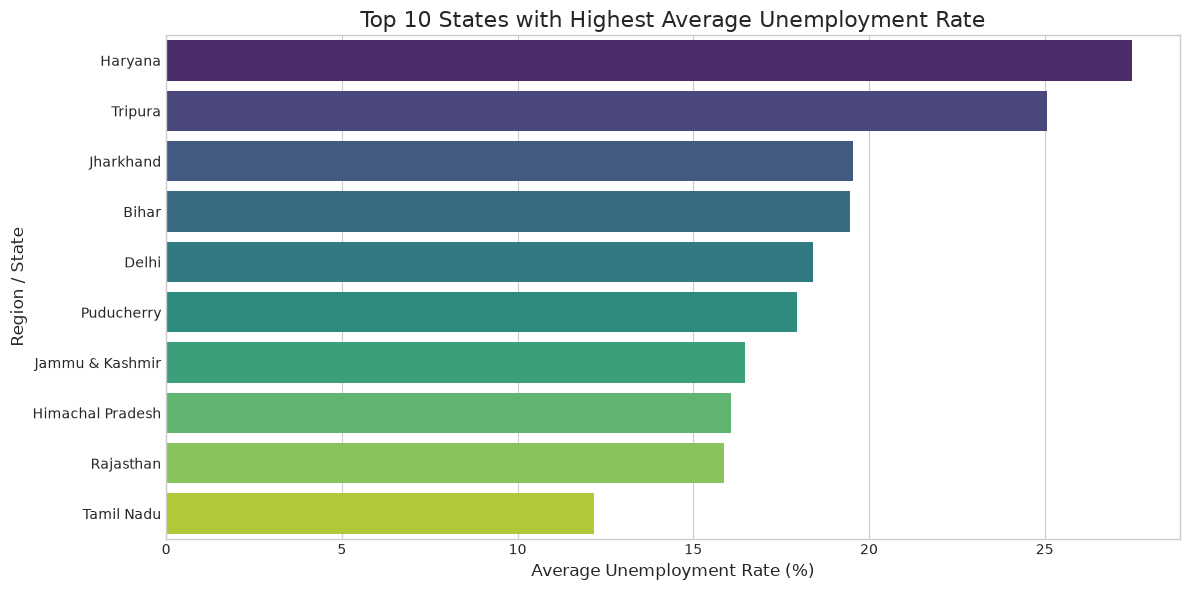

In [5]:
top_10_highest = region_unemployment.head(10)

plt.figure(figsize=(12, 6))
sns.barplot(
    x='Estimated Unemployment Rate (%)', 
    y='Region', 
    data=top_10_highest, 
    palette='viridis'
)
plt.title('Top 10 States with Highest Average Unemployment Rate', fontsize=16)
plt.xlabel('Average Unemployment Rate (%)', fontsize=12)
plt.ylabel('Region / State', fontsize=12)
plt.tight_layout()
plt.show()

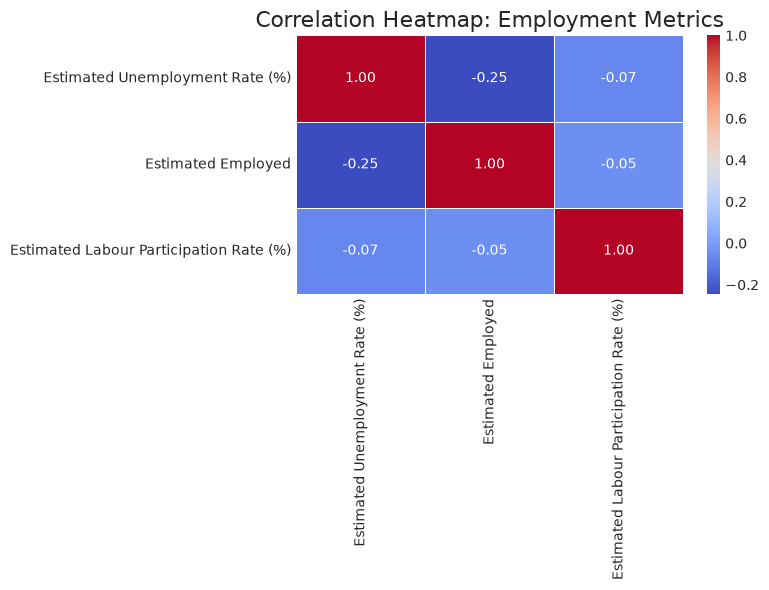

In [6]:
# Select numeric columns
numeric_cols = ['Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)']
correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix, 
    annot=True, 
    cmap='coolwarm', 
    fmt='.2f', 
    linewidths=0.5
)
plt.title('Correlation Heatmap: Employment Metrics', fontsize=16)
plt.tight_layout()
plt.show()

                                         Pre-COVID Mean  Post-COVID Mean
Estimated Unemployment Rate (%)            9.231346e+00     1.296386e+01
Estimated Employed                         1.556273e+07     1.357498e+07
Estimated Labour Participation Rate (%)    4.440365e+01     4.102321e+01


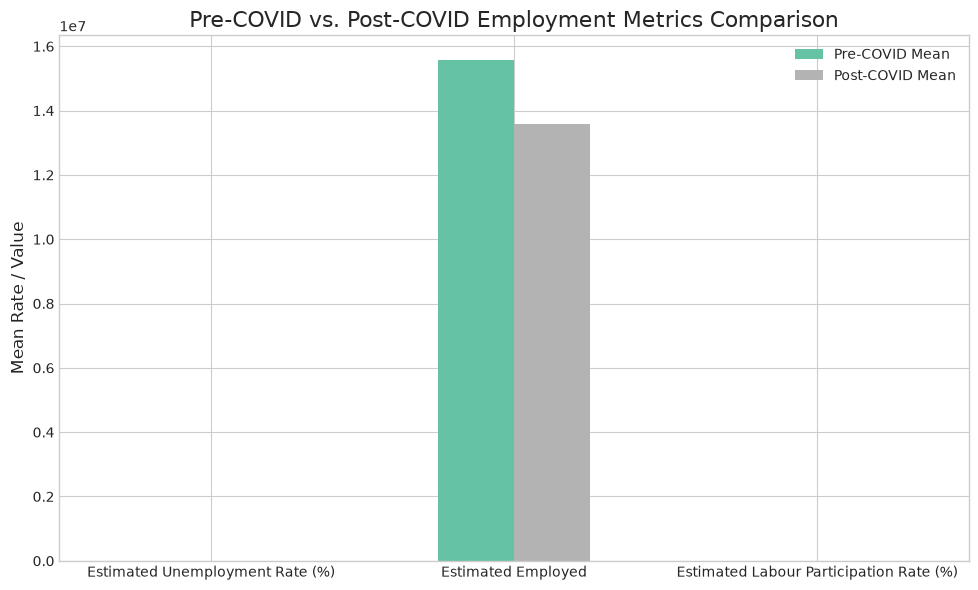

In [7]:
# Define India's national lockdown start date
covid_lockdown_date = pd.to_datetime('2020-03-24')

# Split data
pre_covid = df[df['Date'] < covid_lockdown_date]
post_covid = df[df['Date'] >= covid_lockdown_date]

# Calculate mean rates
pre_mean = pre_covid[['Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)']].mean()
post_mean = post_covid[['Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)']].mean()

comparison_df = pd.DataFrame({
    'Pre-COVID Mean': pre_mean,
    'Post-COVID Mean': post_mean
})

print(comparison_df)

# Visualizing the comparison
comparison_df.plot(kind='bar', figsize=(10, 6), colormap='Set2')
plt.title('Pre-COVID vs. Post-COVID Employment Metrics Comparison', fontsize=16)
plt.ylabel('Mean Rate / Value', fontsize=12)
plt.xticks(rotation=0)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

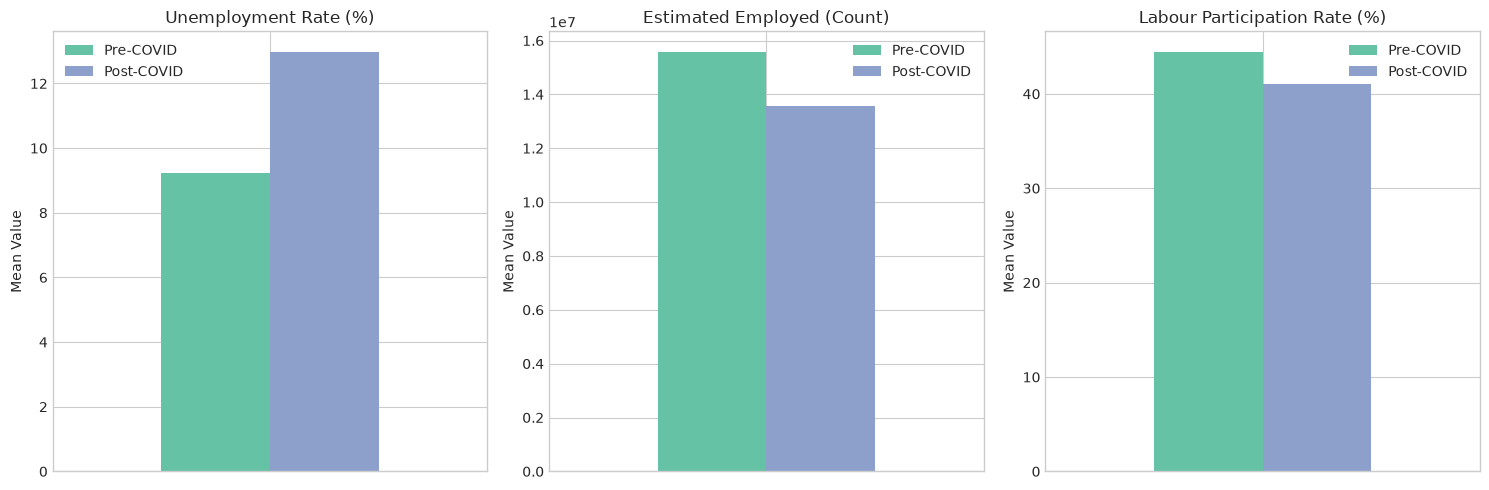

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics = ['Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)']
titles = ['Unemployment Rate (%)', 'Estimated Employed (Count)', 'Labour Participation Rate (%)']

for i, col in enumerate(metrics):
    # Fixed: Wrapped the means inside lists [ ] so Pandas treats them as valid row data
    comparison_subset = pd.DataFrame({
        'Pre-COVID': [pre_covid[col].mean()],
        'Post-COVID': [post_covid[col].mean()]
    })
    
    comparison_subset.plot(kind='bar', ax=axes[i], color=['#66c2a5', '#8da0cb'])
    axes[i].set_title(titles[i])
    axes[i].set_ylabel('Mean Value')
    axes[i].set_xticklabels([''], rotation=0) # Hides the redundant '0' index label on the x-axis

plt.tight_layout()
plt.show()